# Card 01 – Sales & growth
**Question:** sales grow every year – is it real growth (more pieces, more orders) or just higher prices?
Tables: `sales_orders`, `sales_order_items`, `products_catalog`, `sku_variants`. Fiscal year = Oct–Sep.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

files = pd.read_pickle('../clean/cottonil_clean.pkl')

# 3 colours only: navy = main, light grey = context, teal = the ONE thing each chart wants you to look at
NAVY, GREY, TEAL = '#2F4B7C', '#D5DCE6', '#3AA6A0'
BLUE, ORANGE, AQUA, LIGHT = NAVY, TEAL, TEAL, GREY      # old names kept so every notebook uses the same 3 colours
INK = '#4A5568'                                           # text only
plt.rcParams.update({'font.size': 10.5, 'axes.titlesize': 12.5, 'axes.titleweight': 'bold', 'axes.edgecolor': '#d6d5d0',
                     'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'figure.dpi': 110})


def style(ax, title, ylabel=None):
    """Title = the insight, light grid, no box."""
    ax.set_title(title, loc='left', pad=12)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(axis='y', color='#ecebe7'); ax.set_axisbelow(True)
    if ylabel:
        ax.set_ylabel(ylabel)


def save(fig, name):
    fig.savefig(f'../outputs/charts/{name}.png', dpi=150, bbox_inches='tight')


def full_years(d, col='fy'):
    """Complete fiscal years only: FY2019 → FY2026 (Oct–Sep)."""
    return d[(d[col] >= 2019) & (d[col] <= 2026)]


M = lambda x: f'{x / 1e6:,.1f}M'

In [2]:
so, li = full_years(files['orders']), full_years(files['lines'])
fy = so.groupby('fy').agg(orders=('sales_order_id', 'size'), net_sales=('net_before_tax_EGP', 'sum'), discount=('discount_EGP', 'sum'))
fy = fy.join(li.groupby('fy').agg(units=('quantity', 'sum'), gross_profit=('margin_EGP', 'sum')))
fy['margin_%'] = fy.gross_profit / fy.net_sales * 100
fy['avg_order_EGP'] = fy.net_sales / fy.orders
fy['price_per_unit'] = fy.net_sales / fy.units
for col in ['net_sales', 'orders', 'units', 'price_per_unit']:
    fy[col + '_growth_%'] = fy[col].pct_change() * 100
fy.round(1)

,orders,net_sales,discount,units,gross_profit,margin_%,avg_order_EGP,price_per_unit,net_sales_growth_%,orders_growth_%,units_growth_%,price_per_unit_growth_%
fy,,,,,,,,,,,,
2019,40319,19155036.5,865699.9,253025,7347268.8,38.4,475.1,75.7,NaN,NaN,NaN,NaN
2020,45523,24574853.2,1118031.7,289688,9411066.5,38.3,539.8,84.8,28.3,12.9,14.5,12.1
2021,51674,30984117.7,1381503.2,325375,11880311.1,38.3,599.6,95.2,26.1,13.5,12.3,12.3
2022,59343,46332426.8,2106025.5,375763,17678493.9,38.2,780.8,123.3,49.5,14.8,15.5,29.5
2023,69195,74163677.7,3388966.4,436420,28405471.4,38.3,1071.8,169.9,60.1,16.6,16.1,37.8
2024,79327,130958770.8,5890677.5,500525,50350049.7,38.4,1650.9,261.6,76.6,14.6,14.7,54.0
2025,90144,211301372.7,9511462.2,567644,80990032.9,38.3,2344.0,372.2,61.3,13.6,13.4,42.3
2026,99834,289209108.0,13023456.6,620701,110893501.6,38.3,2896.9,465.9,36.9,10.7,9.3,25.2


orders ×2.5 (same as pieces: ~6.3 pieces per order every year)


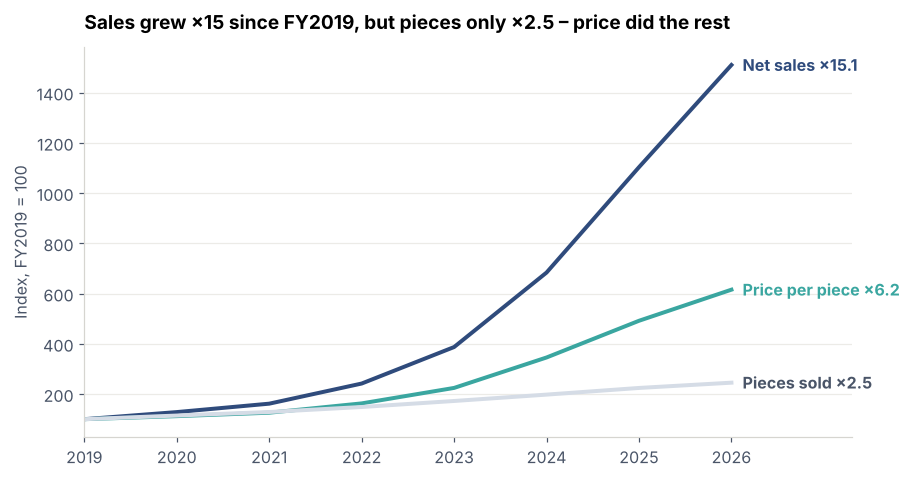

In [3]:
idx = fy[['net_sales', 'units', 'price_per_unit', 'orders']] / fy[['net_sales', 'units', 'price_per_unit', 'orders']].iloc[0] * 100
fig, ax = plt.subplots(figsize=(9, 4.6))
for col, color, label in [('net_sales', BLUE, 'Net sales'), ('price_per_unit', ORANGE, 'Price per piece'), ('units', GREY, 'Pieces sold')]:
    ax.plot(idx.index, idx[col], color=color, lw=2.6)
    ax.text(idx.index[-1] + 0.12, idx[col].iloc[-1], f'{label} ×{idx[col].iloc[-1] / 100:.1f}', va='center', color=INK if color == GREY else color, fontweight='bold')
style(ax, f'Sales grew ×{idx.net_sales.iloc[-1] / 100:.0f} since FY2019, but pieces only ×{idx.units.iloc[-1] / 100:.1f} – price did the rest', 'Index, FY2019 = 100')
ax.set_xlim(2019, 2027.3); ax.set_xticks(idx.index)
print(f'orders ×{idx.orders.iloc[-1] / 100:.1f} (same as pieces: ~6.3 pieces per order every year)')
save(fig, 'c01_sales_vs_units_index')

FY2026: sales +36.9% = pieces +9.3% and price per piece +25.2%


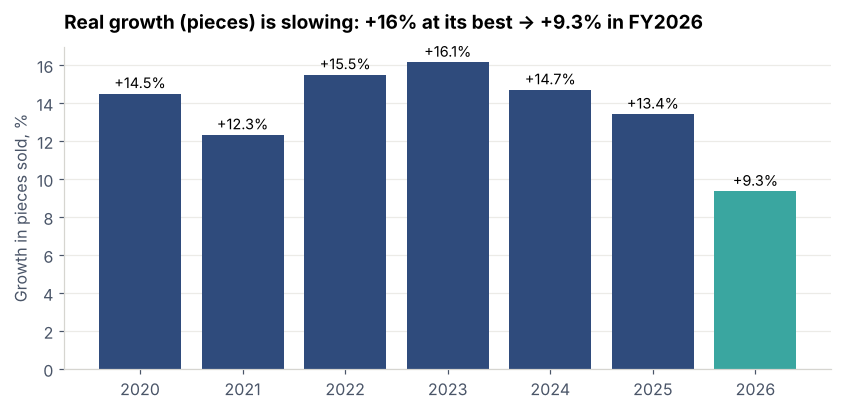

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
g = fy['units_growth_%'].dropna()
bars = ax.bar(g.index, g, color=[ORANGE if y == g.index[-1] else BLUE for y in g.index])
for x, v in g.items():
    ax.text(x, v + 0.3, f'+{v:.1f}%', ha='center', fontsize=9.5)
style(ax, f'Real growth (pieces) is slowing: +{g.max():.0f}% at its best → +{g.iloc[-1]:.1f}% in FY2026', 'Growth in pieces sold, %')
ax.set_xticks(g.index)
save(fig, 'c01_volume_growth')
print('FY2026: sales +%.1f%% = pieces +%.1f%% and price per piece +%.1f%%' % (fy['net_sales_growth_%'].iloc[-1], fy['units_growth_%'].iloc[-1], fy['price_per_unit_growth_%'].iloc[-1]))

In [5]:
print('margin by year: %.1f%% – %.1f%%' % (fy['margin_%'].min(), fy['margin_%'].max()))
ratio = li.unit_cost_EGP / li.unit_price_EGP
print('unit cost ÷ unit price: average %.0f%%, the same in every category:' % (ratio.mean() * 100))
li.assign(ratio=ratio).groupby('category_en').ratio.mean().mul(100).round(1).sort_values().head(3)

margin by year: 38.2% – 38.4%
unit cost ÷ unit price: average 59%, the same in every category:


category_en
Boys pajamas       58.9
Girls underwear    58.9
Men bottoms        58.9
Name: ratio, dtype: float64

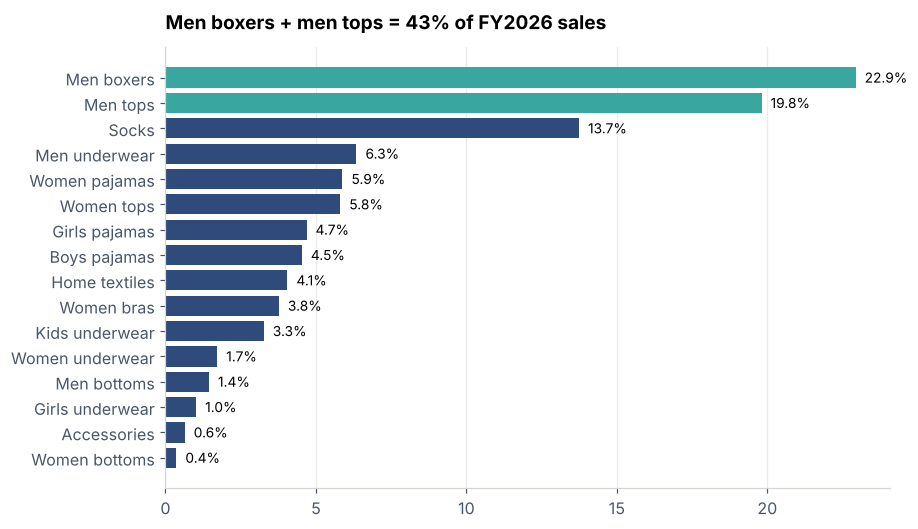

,net,units,gp,share_%,margin_%
category_en,,,,,
Men boxers,66328274.2,69021,25344345.2,22.9,38.2
Men tops,57286300.3,82363,22041747.8,19.8,38.5
Socks,39744001.3,164943,15238973.1,13.7,38.3
Men underwear,18357161.9,34946,7085632.1,6.3,38.6
Women pajamas,17003310.6,14166,6505684.5,5.9,38.3
Women tops,16793313.6,62945,6475610.4,5.8,38.6


In [6]:
f26 = li[li.fy == 2026].groupby('category_en').agg(net=('net_line_EGP', 'sum'), units=('quantity', 'sum'), gp=('margin_EGP', 'sum'))
f26['share_%'] = f26.net / f26.net.sum() * 100
f26['margin_%'] = f26.gp / f26.net * 100
f26 = f26.sort_values('net')
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.barh(f26.index, f26['share_%'], color=[ORANGE if c in f26.index[-2:] else BLUE for c in f26.index])
for i, v in enumerate(f26['share_%']):
    ax.text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=9)
style(ax, f'Men boxers + men tops = {f26["share_%"].iloc[-2:].sum():.0f}% of FY2026 sales')
ax.grid(axis='x', color='#ecebe7'); ax.grid(axis='y', visible=False)
save(fig, 'c01_category_share')
f26.sort_values('net', ascending=False).round(1).head(6)

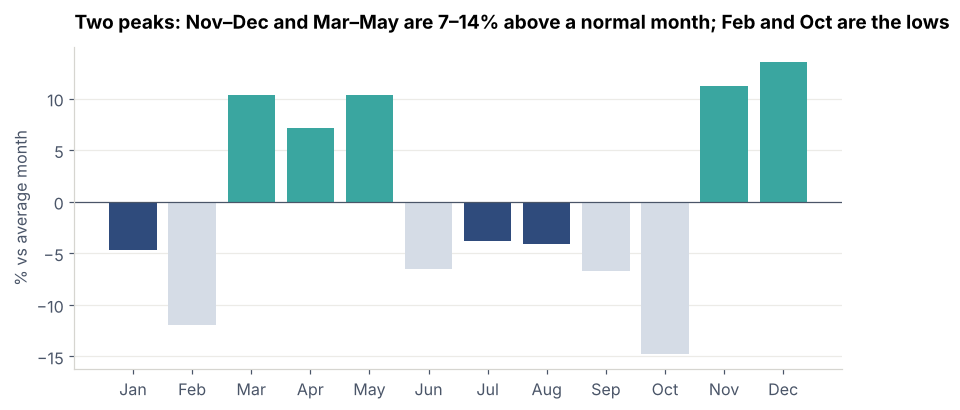

m,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
% vs average month,-4.7,-12.0,10.3,7.1,10.3,-6.5,-3.8,-4.1,-6.7,-14.8,11.2,13.6


In [7]:
s = so[so.fy >= 2020].assign(m=lambda d: d.order_date.dt.month)   # FY2019 has only half of October
s = s.groupby(['fy', 'm']).size().unstack()
season = s.div(s.mean(axis=1), axis=0).mean()
fig, ax = plt.subplots(figsize=(9, 3.8))
names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
ax.bar(names, (season - 1) * 100, color=[ORANGE if v > 1.07 else (GREY if v < 0.95 else BLUE) for v in season])
ax.axhline(0, color=INK, lw=0.8)
style(ax, 'Two peaks: Nov–Dec and Mar–May are 7–14% above a normal month; Feb and Oct are the lows', '% vs average month')
save(fig, 'c01_seasonality')
(season.rename(dict(enumerate(names, 1))) * 100 - 100).round(1).to_frame('% vs average month').T

In [8]:
w = so.groupby(['fy', 'weekday']).size().unstack()
week = (w.div(w.mean(axis=1), axis=0).mean() * 100 - 100).round(1)
week[['Saturday', 'Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']].to_frame('% vs average day').T

weekday,Saturday,Sunday,Monday,Tuesday,Wednesday,Thursday,Friday
% vs average day,6.8,-5.3,-5.5,-5.1,-5.0,7.2,6.9


In [9]:
ch = so.groupby(['fy', 'channel']).net_before_tax_EGP.sum().unstack()
share = ch.div(ch.sum(axis=1), axis=0) * 100
upo = li.groupby('channel').quantity.sum() / so.groupby('channel').size()
print('pieces per order:', upo.round(1).to_dict())
share.round(1)

pieces per order: {'Online': 4.4, 'Store': 4.3, 'Wholesale': 23.9}


channel,Online,Store,Wholesale
fy,,,
2019,12.0,49.4,38.5
2020,12.3,49.3,38.4
2021,12.5,48.8,38.7
2022,12.4,48.9,38.7
2023,12.9,49.7,37.5
2024,12.4,49.1,38.5
2025,12.5,49.0,38.5
2026,12.7,50.1,37.3


### Takeaway (card 01)
- Net sales: **19.2M → 289.2M EGP** (FY2019 → FY2026). Pieces only ×2.5, price per piece ×6.2 (inflation).
- Real growth (pieces) is positive but **slowing: +9.3% in FY2026**, the lowest in 8 years.
- Margin is fixed at **38.3%** because cost is always ~59% of price – so "product profitability" is the same everywhere; the only thing that moves margin is the discount (card 02).
- Real demand signals we can plan on: **seasonality** (Nov–Dec, Mar–May), **Thu–Sat**, the **category mix**, and the **wholesale basket (~24 pieces)**.
- Channel mix is frozen: Store ~50%, Wholesale ~38%, Online ~12.5% every year.